In [1]:
!nvidia-smi
!pip -q install kaggle torchmetrics grad-cam
from google.colab import files
files.upload()  # unggah kaggle.json dari akun Kaggle kamu
!mkdir -p ~/.kaggle && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d paultimothymooney/chest-xray-pneumonia -p /content/data --unzip

Sun Nov  8 06:37:22 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   58C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

mv: cannot stat 'kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
100% 2.29G/2.29G [01:53<00:00, 21.8MB/s]



# baca data, buang duplikat, ekstrak ID pasien

In [2]:
import re, hashlib, pandas as pd
from pathlib import Path

rows = [{'path': str(p), 'name': p.name, 'label': p.parent.name}
        for p in Path('/content/data').rglob('*')
        if p.suffix.lower() in {'.jpeg', '.jpg', '.png'} and '__MACOSX' not in p.parts]
df = pd.DataFrame(rows)
print('sebelum dedup:', len(df))

df['hash'] = df['path'].map(lambda p: hashlib.md5(open(p, 'rb').read()).hexdigest())
df = df.drop_duplicates('hash').reset_index(drop=True)
print('sesudah dedup:', len(df))

def get_pid(r):
    m = re.search(r'person(\d+)', r['name']) or re.search(r'IM-(\d+)', r['name'])
    return (r['label'][0] + '_' + m.group(1)) if m else None

df['patient'] = df.apply(get_pid, axis=1)
print(df['label'].value_counts())
print('tanpa ID pasien:', df['patient'].isna().sum(), '| pasien unik:', df['patient'].nunique())

sebelum dedup: 11712
sesudah dedup: 5824
label
PNEUMONIA    4245
NORMAL       1579
Name: count, dtype: int64
tanpa ID pasien: 0 | pasien unik: 2789


# split per pasien 70/15/15

In [3]:
from sklearn.model_selection import GroupShuffleSplit

df['patient'] = df['patient'].fillna(df['name'])  # tanpa ID: dianggap pasien sendiri
gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=42)
trv, te = next(gss.split(df, groups=df['patient']))
trv_df, test_df = df.iloc[trv], df.iloc[te]

gss2 = GroupShuffleSplit(n_splits=1, test_size=0.15/0.85, random_state=42)
tr, va = next(gss2.split(trv_df, groups=trv_df['patient']))
train_df, val_df = trv_df.iloc[tr], trv_df.iloc[va]

for n, d in [('train', train_df), ('val', val_df), ('test', test_df)]:
    print(n, len(d), d['label'].value_counts(normalize=True).round(2).to_dict())

assert not (set(train_df.patient) & set(test_df.patient))
assert not (set(train_df.patient) & set(val_df.patient))

train 4013 {'PNEUMONIA': 0.73, 'NORMAL': 0.27}
val 871 {'PNEUMONIA': 0.72, 'NORMAL': 0.28}
test 940 {'PNEUMONIA': 0.71, 'NORMAL': 0.29}


# simpan split ke Drive dan lihat sampel gambar

Mounted at /content/drive


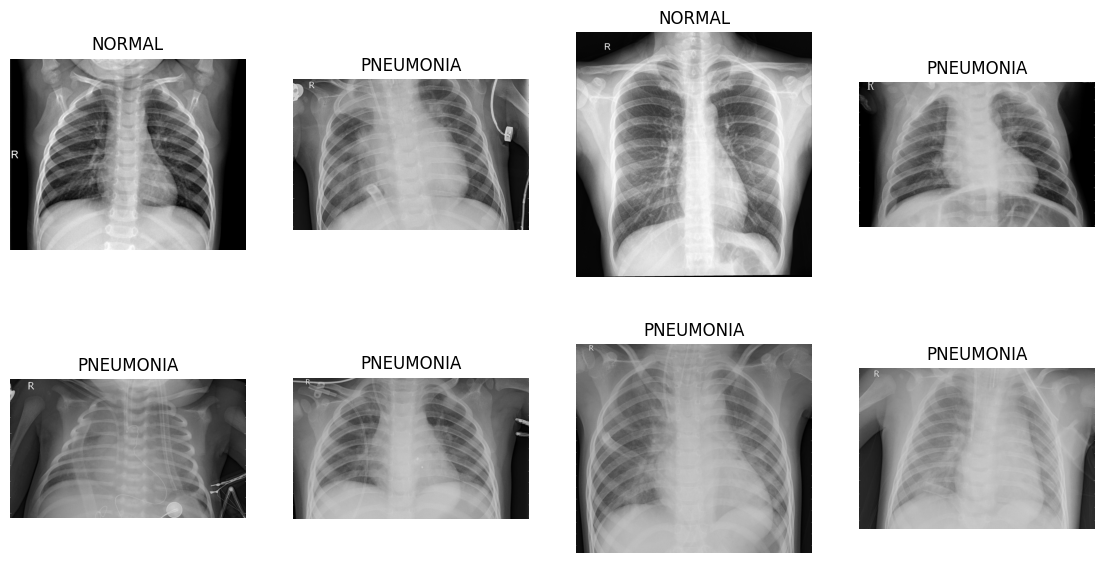

                 w            h
count   300.000000   300.000000
mean   1299.816667   941.576667
std     378.225221   392.713437
min     439.000000   173.000000
25%    1040.000000   664.000000
50%    1248.000000   848.000000
75%    1547.000000  1172.000000
max    2624.000000  2601.000000


In [4]:
from google.colab import drive
from PIL import Image
import matplotlib.pyplot as plt
drive.mount('/content/drive')

out = Path('/content/drive/MyDrive/pneumonia-cxr'); out.mkdir(exist_ok=True)
for n, d in [('train', train_df), ('val', val_df), ('test', test_df)]:
    d.to_csv(out / f'{n}.csv', index=False)

fig, ax = plt.subplots(2, 4, figsize=(14, 7))
for a, (_, r) in zip(ax.ravel(), train_df.sample(8, random_state=1).iterrows()):
    a.imshow(Image.open(r['path']), cmap='gray'); a.set_title(r['label']); a.axis('off')
plt.show()

sizes = [Image.open(p).size for p in train_df['path'].sample(300, random_state=1)]
print(pd.DataFrame(sizes, columns=['w', 'h']).describe())

# dataset, augmentasi, dataloader, class weight

In [5]:
import torch, numpy as np
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T

CLASSES = ['NORMAL', 'PNEUMONIA']
norm = T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
train_tf = T.Compose([T.Resize((256, 256)), T.RandomResizedCrop(224, scale=(0.85, 1.0)),
                      T.RandomRotation(10), T.ColorJitter(brightness=0.2, contrast=0.2),
                      T.ToTensor(), norm])
eval_tf = T.Compose([T.Resize(256), T.CenterCrop(224), T.ToTensor(), norm])

class CXR(Dataset):
    def __init__(self, df, tf):
        self.paths = df['path'].tolist()
        self.y = [CLASSES.index(l) for l in df['label']]
        self.tf = tf
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        return self.tf(Image.open(self.paths[i]).convert('RGB')), self.y[i]

mk = lambda d, tf, sh: DataLoader(CXR(d, tf), batch_size=32, shuffle=sh, num_workers=2, pin_memory=True)
train_loader, val_loader, test_loader = mk(train_df, train_tf, True), mk(val_df, eval_tf, False), mk(test_df, eval_tf, False)

counts = np.bincount(train_loader.dataset.y)
class_w = torch.tensor(len(train_loader.dataset) / (2 * counts), dtype=torch.float)
print('counts:', counts, '| class weights:', class_w)

x, y = next(iter(train_loader))
print(x.shape, y[:8])

counts: [1064 2949] | class weights: tensor([1.8858, 0.6804])
torch.Size([32, 3, 224, 224]) tensor([1, 1, 1, 1, 0, 1, 1, 1])


# model baseline ResNet50, training loop, checkpoint ke Drive

In [6]:
import time, torch.nn as nn
from torchvision import models
from sklearn.metrics import roc_auc_score, confusion_matrix

device = 'cuda'
model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
model.fc = nn.Linear(model.fc.in_features, 2)
model = model.to(device)

crit = nn.CrossEntropyLoss(weight=class_w.to(device))
opt = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
EPOCHS = 8
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
scaler = torch.amp.GradScaler('cuda')

@torch.no_grad()
def evaluate(loader):
    model.eval(); ys, ps, loss_sum = [], [], 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        with torch.autocast('cuda'):
            o = model(x)
        loss_sum += crit(o.float(), y).item() * len(y)
        ps += torch.softmax(o.float(), 1)[:, 1].cpu().tolist(); ys += y.cpu().tolist()
    ys, ps = np.array(ys), np.array(ps)
    tn, fp, fn, tp = confusion_matrix(ys, ps > 0.5).ravel()
    return {'loss': round(loss_sum / len(ys), 4), 'auroc': round(roc_auc_score(ys, ps), 4),
            'sens': round(tp / (tp + fn), 4), 'spec': round(tn / (tn + fp), 4)}

best, bad, PATIENCE = 0, 0, 3
for ep in range(EPOCHS):
    model.train(); t0 = time.time(); run = 0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        opt.zero_grad(set_to_none=True)
        with torch.autocast('cuda'):
            loss = crit(model(x).float(), y)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        run += loss.item() * len(y)
    sched.step()
    m = evaluate(val_loader)
    print(f"ep{ep+1} train_loss {run/len(train_loader.dataset):.4f} | val {m} | {time.time()-t0:.0f}s")
    torch.save(model.state_dict(), out / 'last.pt')
    if m['auroc'] > best:
        best, bad = m['auroc'], 0; torch.save(model.state_dict(), out / 'best.pt')
    else:
        bad += 1
        if bad >= PATIENCE: print('early stop'); break

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:02<00:00, 47.0MB/s]


ep1 train_loss 0.2426 | val {'loss': 0.131, 'auroc': np.float64(0.9873), 'sens': np.float64(0.9729), 'spec': np.float64(0.8889)} | 120s
ep2 train_loss 0.1126 | val {'loss': 0.1098, 'auroc': np.float64(0.9914), 'sens': np.float64(0.9825), 'spec': np.float64(0.9136)} | 104s
ep3 train_loss 0.0878 | val {'loss': 0.1413, 'auroc': np.float64(0.9874), 'sens': np.float64(0.9602), 'spec': np.float64(0.9177)} | 109s
ep4 train_loss 0.0694 | val {'loss': 0.1157, 'auroc': np.float64(0.9901), 'sens': np.float64(0.9904), 'spec': np.float64(0.9218)} | 107s
ep5 train_loss 0.0473 | val {'loss': 0.1249, 'auroc': np.float64(0.9898), 'sens': np.float64(0.9761), 'spec': np.float64(0.93)} | 106s
early stop


# pilih threshold di val, evaluasi test, interval kepercayaan

In [7]:
from sklearn.metrics import roc_curve
model.load_state_dict(torch.load(out / 'best.pt')); model.eval()

@torch.no_grad()
def predict(loader):
    ys, ps = [], []
    for x, y in loader:
        with torch.autocast('cuda'):
            o = model(x.to(device))
        ps += torch.softmax(o.float(), 1)[:, 1].cpu().tolist(); ys += y.tolist()
    return np.array(ys), np.array(ps)

yv, pv = predict(val_loader)
fpr, tpr, thr = roc_curve(yv, pv)
ok = tpr >= 0.98
t = float(thr[ok][np.argmin(fpr[ok])])   # specificity tertinggi dengan sensitivity val >= 0.98
print('threshold dari val:', round(t, 4))

yt, pt = predict(test_loader)
def metrics(y, p, t):
    tn, fp, fn, tp = confusion_matrix(y, p >= t).ravel()
    return roc_auc_score(y, p), tp / (tp + fn), tn / (tn + fp)

auc, sens, spec = metrics(yt, pt, t)
print(f'TEST  AUROC {auc:.4f} | sens {sens:.4f} | spec {spec:.4f}')
print(confusion_matrix(yt, pt >= t))

rng = np.random.default_rng(0); bs = []
for _ in range(1000):
    i = rng.integers(0, len(yt), len(yt)); bs.append(metrics(yt[i], pt[i], t))
lo, hi = np.percentile(bs, [2.5, 97.5], axis=0)
for n, a, b in zip(['AUROC', 'sens', 'spec'], lo, hi): print(f'{n} 95% CI: [{a:.3f}, {b:.3f}]')

pd.DataFrame({'path': test_df['path'].values, 'y': yt, 'prob': pt}).to_csv(out / 'test_preds.csv', index=False)

threshold dari val: 0.5162
TEST  AUROC 0.9882 | sens 0.9775 | spec 0.9228
[[251  21]
 [ 15 653]]
AUROC 95% CI: [0.979, 0.995]
sens 95% CI: [0.966, 0.988]
spec 95% CI: [0.889, 0.953]


# Grad-CAM untuk TP, TN, FP, FN

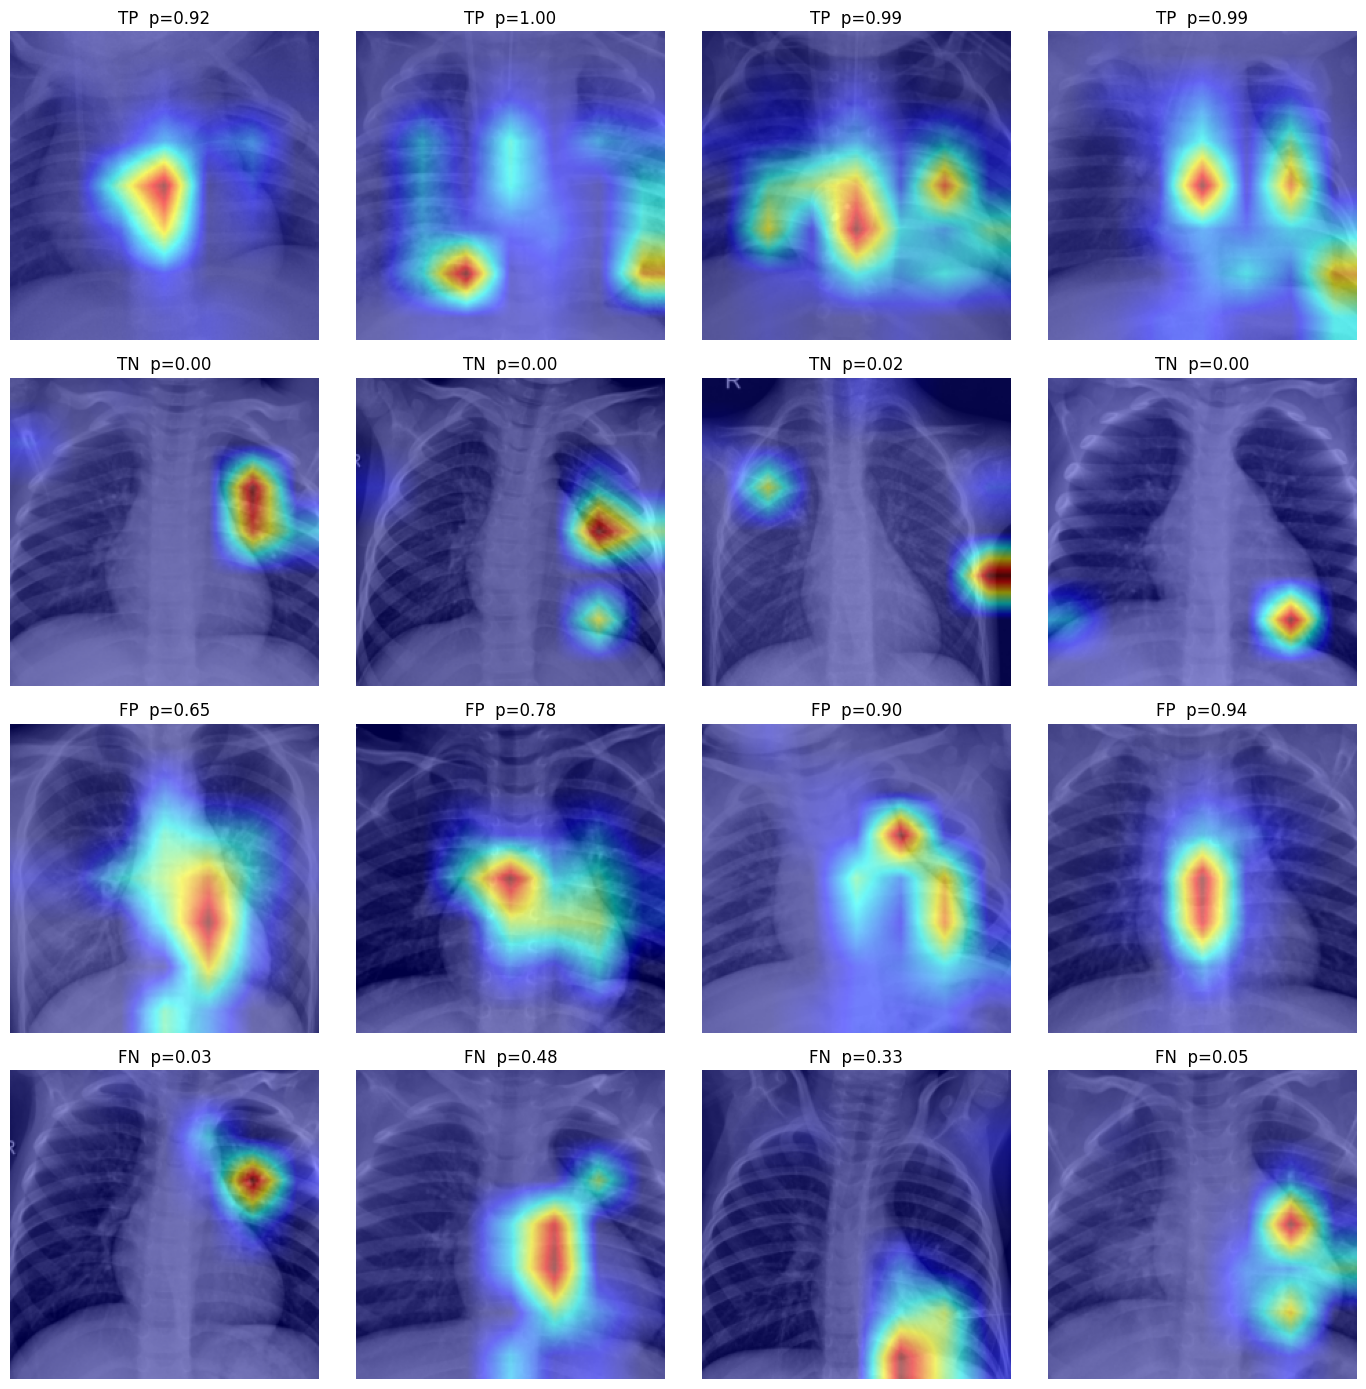

In [8]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

tdf = test_df.reset_index(drop=True).assign(prob=pt, y=yt, pred=(pt >= t).astype(int))
groups = {'TP': (tdf.y == 1) & (tdf.pred == 1), 'TN': (tdf.y == 0) & (tdf.pred == 0),
          'FP': (tdf.y == 0) & (tdf.pred == 1), 'FN': (tdf.y == 1) & (tdf.pred == 0)}
cam = GradCAM(model=model, target_layers=[model.layer4[-1]])
view = T.Compose([T.Resize(256), T.CenterCrop(224)])

fig, ax = plt.subplots(4, 4, figsize=(14, 14))
for a in ax.ravel(): a.axis('off')
for r, (name, mask) in enumerate(groups.items()):
    sub = tdf[mask].sample(min(4, int(mask.sum())), random_state=0)
    for c, (_, row) in enumerate(sub.iterrows()):
        img = Image.open(row['path']).convert('RGB')
        g = cam(input_tensor=eval_tf(img).unsqueeze(0).to(device), targets=[ClassifierOutputTarget(1)])[0]
        rgb = np.asarray(view(img), dtype=np.float32) / 255.0
        ax[r][c].imshow(show_cam_on_image(rgb, g, use_rgb=True))
        ax[r][c].set_title(f"{name}  p={row['prob']:.2f}")
plt.tight_layout(); plt.savefig(out / 'gradcam.png', dpi=120); plt.show()

# uji ketergantungan, pakai val, bukan test

In [9]:
def masked_loader(df, kind):
    class M(CXR):
        def __getitem__(self, i):
            x, y = super().__getitem__(i)
            x = x.clone()
            if kind == 'border':      # sisakan area tengah, buang 20% tepi tiap sisi
                m = torch.zeros_like(x); m[:, 45:179, 45:179] = 1; x = x * m
            elif kind == 'center':    # buang area mediastinum
                x[:, 56:168, 70:154] = 0
            return x, y
    return DataLoader(M(df, eval_tf), batch_size=32, num_workers=2)

print('val asli          AUROC', round(roc_auc_score(yv, pv), 4))
for kind in ['border', 'center']:
    y_, p_ = predict(masked_loader(val_df, kind))
    print(f'val tanpa {kind:7s} AUROC', round(roc_auc_score(y_, p_), 4))

val asli          AUROC 0.9914
val tanpa border  AUROC 0.7612
val tanpa center  AUROC 0.9849


# uji bertahap yang lebih adil (masih pakai val)

In [10]:
def occluded_loader(df, mode, p):
    class M(CXR):
        def __getitem__(self, i):
            x, y = super().__getitem__(i)
            keep = torch.zeros(1, 224, 224)
            keep[:, p:224-p, p:224-p] = 1
            if mode == 'ring_only': keep = 1 - keep
            return x * keep, y
    return DataLoader(M(df, eval_tf), batch_size=32, num_workers=2)

print('asli', round(roc_auc_score(yv, pv), 4))
for p in [8, 16, 28, 45, 70]:
    y_, p_ = predict(occluded_loader(val_df, 'crop', p))
    print(f'buang tepi {p:2d}px : AUROC {roc_auc_score(y_, p_):.4f}')
for p in [28, 45, 70]:
    y_, p_ = predict(occluded_loader(val_df, 'ring_only', p))
    print(f'hanya cincin tepi {p:2d}px : AUROC {roc_auc_score(y_, p_):.4f}')

asli 0.9914
buang tepi  8px : AUROC 0.9823
buang tepi 16px : AUROC 0.9725
buang tepi 28px : AUROC 0.9328
buang tepi 45px : AUROC 0.7612
buang tepi 70px : AUROC 0.8755
hanya cincin tepi 28px : AUROC 0.7242
hanya cincin tepi 45px : AUROC 0.9433
hanya cincin tepi 70px : AUROC 0.9867


# baseline “bodoh”

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def feats(path):
    im = Image.open(path); im.draft('L', (128, 128))
    a = np.asarray(im.convert('L').resize((32, 32)), dtype=np.float32) / 255
    return np.r_[a.ravel(), a.mean(), a.std(), np.percentile(a, [5, 50, 95])]

Xtr = np.stack([feats(p) for p in train_df['path']])
Xva = np.stack([feats(p) for p in val_df['path']])
ytr = np.array([CLASSES.index(l) for l in train_df['label']])

def fit_eval(cols):
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight='balanced'))
    clf.fit(Xtr[:, cols], ytr)
    return round(roc_auc_score(yv, clf.predict_proba(Xva[:, cols])[:, 1]), 4)

print('32x32 piksel mentah   AUROC val:', fit_eval(slice(None)))
print('hanya statistik global AUROC val:', fit_eval(slice(-5, None)))

32x32 piksel mentah   AUROC val: 0.9663
hanya statistik global AUROC val: 0.8462


# ekspor bobot dan metadata untuk deploy

In [12]:
import json
sd = {k: (v.half() if v.is_floating_point() else v) for k, v in model.state_dict().items()}
torch.save(sd, out / 'best_fp16.pt')   # ~50 MB, lebih ringan dari bobot asli

meta = {'classes': CLASSES, 'threshold': t,
        'test': {'auroc': round(float(auc), 4), 'sensitivity': round(float(sens), 4), 'specificity': round(float(spec), 4),
                 'auroc_ci95': [round(float(lo[0]), 3), round(float(hi[0]), 3)],
                 'sens_ci95': [round(float(lo[1]), 3), round(float(hi[1]), 3)],
                 'spec_ci95': [round(float(lo[2]), 3), round(float(hi[2]), 3)]},
        'baseline_val_auroc': {'logreg_32x32': 0.9663, 'global_stats_only': 0.8462}}
json.dump(meta, open(out / 'meta.json', 'w'), indent=2)
print((out / 'best_fp16.pt').stat().st_size / 1e6, 'MB')

47.231115 MB
